# 线性回归：医疗保险费用预测
**运行环境**：Python 3.13 (Anaconda).

## 0. 导入

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# 中文/负号显示设置
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Microsoft YaHei")

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")
df = pd.read_csv("insurance.csv")
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900000,0,yes,southwest,"16,884.924000"
1,18,male,33.770000,1,no,southeast,"1,725.552300"
2,28,male,33.000000,3,no,southeast,"4,449.462000"
3,33,male,22.705000,0,no,northwest,"21,984.470610"
4,32,male,28.880000,0,no,northwest,"3,866.855200"
5,31,female,25.740000,0,no,southeast,"3,756.621600"
6,46,female,33.440000,1,no,southeast,"8,240.589600"
7,37,female,27.740000,3,no,northwest,"7,281.505600"
8,37,male,29.830000,2,no,northeast,"6,406.410700"
9,60,female,25.840000,0,no,northwest,"28,923.136920"


## 1. 因变量 charges 分布的直方图, 以验证是否为正态分布

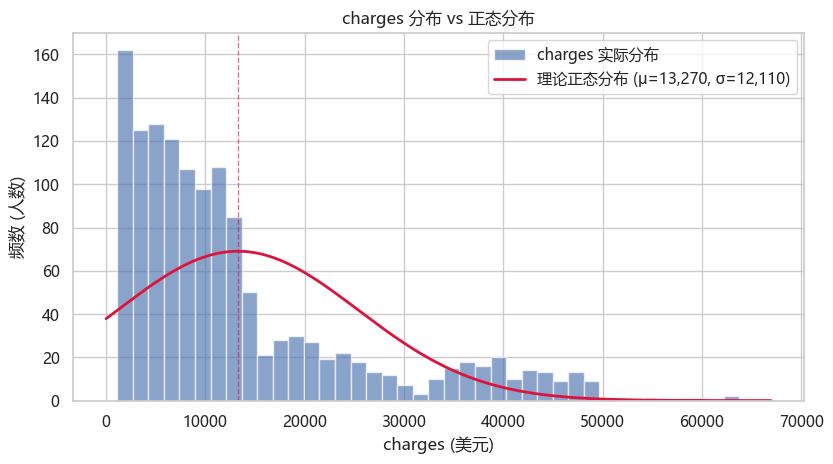

In [211]:
mu, sigma, n = df["charges"].mean(), df["charges"].std(ddof=1), len(df)
fig, ax = plt.subplots(figsize=(8.5, 4.8))

counts, bins, _ = ax.hist(df["charges"], bins=40, color="#4C72B0", alpha=0.65,
                          edgecolor="white", label="charges 实际分布")

# 参考曲线: 同均值同标准差的正态分布
x = np.linspace(0, df["charges"].max() * 1.05, 500)
bin_width = bins[1] - bins[0]
ax.plot(x, stats.norm.pdf(x, mu, sigma) * n * bin_width,
        color="crimson", lw=2, label=f"理论正态分布 (μ={mu:,.0f}, σ={sigma:,.0f})")

ax.axvline(mu, color="crimson", ls="--", lw=1, alpha=0.6)
ax.set_title("charges 分布 vs 正态分布")
ax.set_xlabel("charges (美元)")
ax.set_ylabel("频数 (人数)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**结论**: 直方图呈明显的**右偏单峰**形态 (长尾分布), 而不是正态分布对称的钟形.

## 2. 非数值型特征的频数分布图 + sex 与 smoker 的散点气泡图

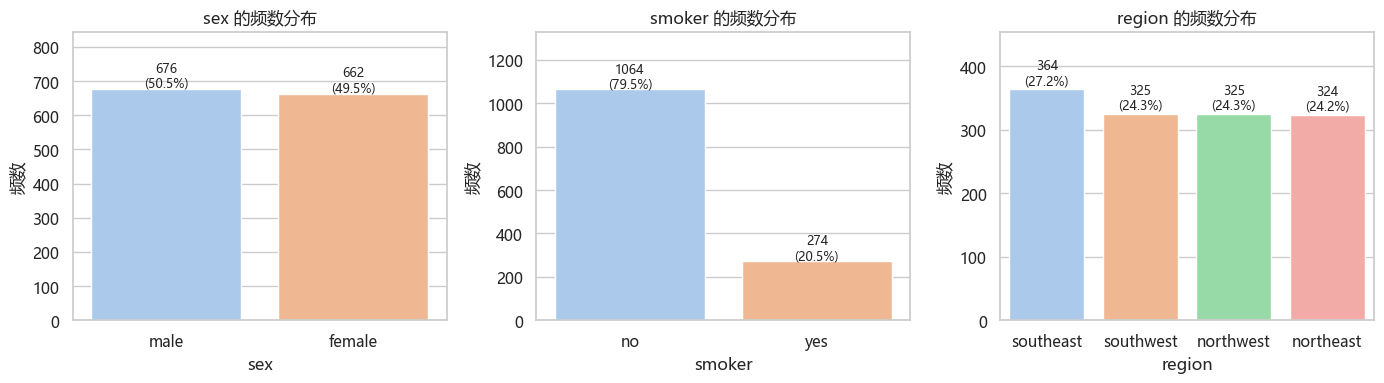

In [212]:
cat_cols = ["sex", "smoker", "region"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cat_cols):
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax,
                palette="pastel", hue=counts.index, legend=False)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 8, f"{v}\n({v/len(df):.1%})", ha="center", fontsize=9)
    ax.set_title(f"{col} 的频数分布")
    ax.set_xlabel(col)
    ax.set_ylabel("频数")
    ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout()
plt.show()

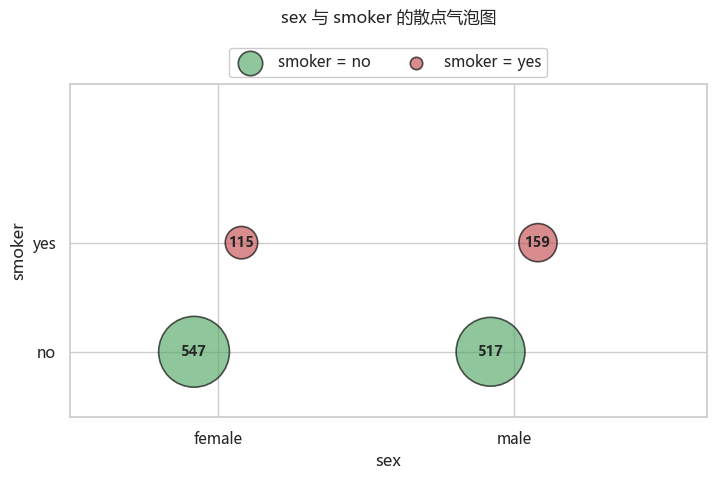

In [213]:
bubble = pd.crosstab(df["sex"], df["smoker"])
x = np.arange(len(bubble.index))
fig, ax = plt.subplots(figsize=(7.5, 5.2))
colors = {"yes": "#C44E52", "no": "#55A868"}

for j, smk in enumerate(bubble.columns):
    sizes = bubble[smk].values / bubble.values.max() * 2600
    ax.scatter(x + (j - 0.5) * 0.16, [j] * len(x), s=sizes,
               color=colors[smk], alpha=0.65, edgecolors="black", linewidths=1.2,
               label=f"smoker = {smk}")
    for i, (size, val) in enumerate(zip(sizes, bubble[smk].values)):
        ax.text(x[i] + (j - 0.5) * 0.16, j, f"{val}", ha="center", va="center",
                fontsize=10, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(bubble.index)
ax.set_yticks(range(len(bubble.columns)))
ax.set_yticklabels(bubble.columns)
ax.set_xlabel("sex")
ax.set_ylabel("smoker")
ax.set_title("sex 与 smoker 的散点气泡图", y=1.16)
ax.set_xlim(-0.5, len(bubble.index) - 0.35)
ax.set_ylim(-0.6, len(bubble.columns) + 0.45)
ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, 1.0),
          ncol=2, markerscale=0.35, framealpha=1.0, facecolor="white")
fig.subplots_adjust(top=0.76, bottom=0.12, left=0.12, right=0.97)
plt.show()

## 3. 数值型特征 age、bmi、children、charges 的相关系数矩阵

Pearson 相关系数矩阵:
              age      bmi  children  charges
age      1.000000 0.109300  0.042500 0.299000
bmi      0.109300 1.000000  0.012800 0.198300
children 0.042500 0.012800  1.000000 0.068000
charges  0.299000 0.198300  0.068000 1.000000


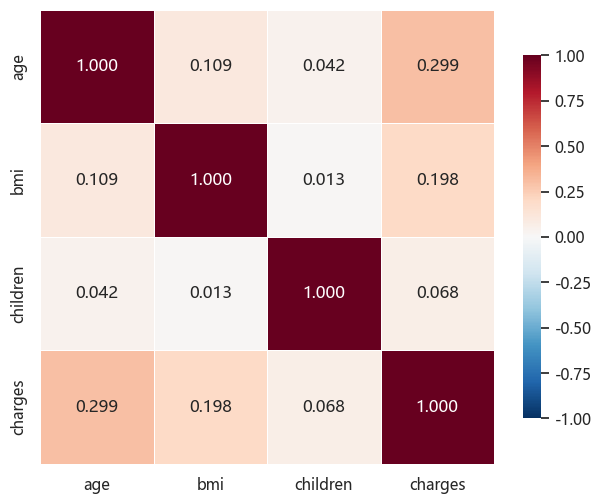

In [214]:
num_cols = ["age", "bmi", "children", "charges"]
corr_pearson = df[num_cols].corr(method="pearson")
corr_spearman = df[num_cols].corr(method="spearman")

print("Pearson 相关系数矩阵:")
print(corr_pearson.round(4).to_string())

corr_pearson = df[["age", "bmi", "children", "charges"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(corr_pearson, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.6, cbar_kws={"shrink": 0.8}, ax=ax)
plt.tight_layout()
plt.show()

## 4. 对 3 个非数值型特征编码

**编码声明:** `sex`（male/female）、`smoker`（yes/no）、`region` (4 个地区) 都是**名义型**变量, 类别之间没有大小先后之分. 对 `region` 使用顺序编码强行赋予`0,1,2,3` 会虚构出不恰当的序关系, 模型系数因此既不可解释也不稳定. 根据老师建议, 此处改用**独热编码**, 即为每个类别生成一个 0/1 哑变量, 类别地位完全平等.

In [215]:
df_enc = df.copy()
df_enc = pd.get_dummies(df_enc, columns=["sex", "smoker", "region"], drop_first=True)
dummy_cols = [c for c in df_enc.columns if df_enc[c].dtype == bool]
df_enc[dummy_cols] = df_enc[dummy_cols].astype(int)

print("独热编码后的数据:")
display(df_enc.head())

独热编码后的数据:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900000,0,"16,884.924000",0,1,0,0,1
1,18,33.770000,1,"1,725.552300",1,0,0,1,0
2,28,33.000000,3,"4,449.462000",1,0,0,1,0
3,33,22.705000,0,"21,984.470610",1,0,1,0,0
4,32,28.880000,0,"3,866.855200",1,0,1,0,0


## 5. 线性回归建模: 自编梯度下降法 vs sklearn 封装函数

要求: 随机 20% 作测试集、80% 作训练集; 在测试集上计算 **MSE** 与 **R²**.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

FEATURES = ["age", "bmi", "children", "sex_male", "smoker_yes",
            "region_northwest", "region_southeast", "region_southwest"]
X = df_enc[FEATURES].to_numpy(dtype=float)
y = df_enc["charges"].to_numpy(dtype=float)

# 随机划分
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=520)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# 梯度下降
def add_intercept(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])

def compute_cost(X_b, y, theta):
    m = len(y)
    residual = X_b @ theta - y
    return residual @ residual / (2 * m)

def gradient_descent(X_b, y, alpha=0.1, n_iter=5000, tol=1e-7):
    m, n = X_b.shape
    theta = np.zeros(n)
    cost_history = [compute_cost(X_b, y, theta)]
    for _ in range(n_iter):
        theta = theta - alpha * (X_b.T @ (X_b @ theta - y) / m)
        cost = compute_cost(X_b, y, theta)
        if abs(cost_history[-1] - cost) < tol:
            break
        cost_history.append(cost)
    return theta

X_train_b = add_intercept(X_train_s)
X_test_b = add_intercept(X_test_s)
theta_gd = gradient_descent(X_train_b, y_train, alpha=0.1, n_iter=5000, tol=1e-7)

# sklearn 封装函数
model_sk = LinearRegression().fit(X_train_s, y_train)

# 测试集上的性能评价
print("测试集上的性能评价:")
y_pred_gd = X_test_b @ theta_gd
y_pred_sk = model_sk.predict(X_test_s)
for name, pred in [("gradient descent", y_pred_gd),
                   ("sklearn LinearRegression", y_pred_sk)]:
    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print(f"{name:<26s} MSE = {mse:>14,.2f}   R2 = {r2:.4f}")

测试集上的性能评价:
gradient descent           MSE =  32,729,281.04   R2 = 0.7869
sklearn LinearRegression   MSE =  32,729,280.39   R2 = 0.7869


**结论**: 自编梯度下降法与 sklearn 封装函数得出的 MSE 和 R2 相同.

## 6. 引入非线性关系: age²、bmi30、bmi30 × smoker

In [217]:
df_nl = df_enc.copy()
df_nl["age2"] = df_nl["age"] ** 2
df_nl["bmi30"] = (df_nl["bmi"] >= 30).astype(int)
df_nl["bmi30_smoker"] = df_nl["bmi30"] * df_nl["smoker_yes"]

NEW_FEATURES = ["age2", "bmi30", "bmi30_smoker"]
FEATURES_NL = FEATURES + NEW_FEATURES

# 使用与第 5 题完全相同的划分索引，保证可比性
X_nl = df_nl[FEATURES_NL].to_numpy(dtype=float)
Xnl_train, Xnl_test, ynl_train, ynl_test = train_test_split(
    X_nl, y, test_size=0.2, random_state=520)

scaler_nl = StandardScaler().fit(Xnl_train)
Xnl_train_s = scaler_nl.transform(Xnl_train)
Xnl_test_s = scaler_nl.transform(Xnl_test)
model_nl = LinearRegression().fit(Xnl_train_s, ynl_train)
y_pred_nl = model_nl.predict(Xnl_test_s)

# 线性模型 vs 加入非线性项的模型
def evaluate(name, y_true, y_pred):
    return {
        "模型": name,
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

res_q6 = pd.DataFrame([
    evaluate("第 5 题线性模型", y_test, y_pred_sk),
    evaluate("加入非线性关系后", y_test, y_pred_nl),
])
res_q6["MSE"] = res_q6["MSE"].round(2)
res_q6["R2"] = res_q6["R2"].round(4)
display(res_q6)

m1, m2 = res_q6.iloc[0], res_q6.iloc[1]
print(f"MSE  下降: {m1['MSE'] - m2['MSE']:,.0f}  ({1 - m2['MSE']/m1['MSE']:.2%})")
print(f"R2   提升: {m2['R2'] - m1['R2']:.4f}")

,模型,MSE,R2
0,第 5 题线性模型,"32,729,280.390000",0.786900
1,加入非线性关系后,"14,705,399.080000",0.904300


MSE  下降: 18,023,881  (55.07%)
R2   提升: 0.1174


**结论**: 模型性能有较显著的提高.